# Supermarket Sales Analysis

This project analyzes supermarket sales data to identify sales trends, compare branch performance, evaluate product categories, and generate actionable business insights.

## Project Objectives

- Assess data quality and understand the dataset.
- Analyze sales performance across branches and product lines.
- Identify monthly sales trends.
- Calculate key business metrics.
- Develop data-driven business recommendations.

## Tools and Technologies

- **Python:** Programming language used for the analysis.
- **Pandas:** Data loading, cleaning, and manipulation.
- **Matplotlib:** Data visualization.
- **Seaborn:** Statistical data visualization.
- **Google Colab:** Environment used to develop and run the analysis.

## 1. Data Loading and Understanding

The dataset was loaded into Python using Pandas. Initial exploration was performed to understand the dataset structure, column names, data types, and descriptive statistics.

The dataset contains 1,000 rows and 17 columns.

In [35]:
import pandas as pd

df = pd.read_csv('/SuperMarket Analysis.csv')

df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [36]:
# Display the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display the available columns
print("\nAvailable columns:")
print(df.columns.tolist())

# Display data types and non-null values
df.info()

Dataset dimensions: (1000, 17)

Available columns:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-n

## 2. Data Quality Checks

Data quality checks were performed to identify missing values and duplicate records. The dataset contains no missing values and no fully duplicated rows.

In [37]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check for missing values
print("\nMissing values by column:")
print(df.isnull().sum())

Duplicate rows: 0

Missing values by column:
Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Sales                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64


In [10]:
# Display descriptive statistics for numerical columns
df.describe()

,Unit price,Quantity,Tax 5%,Sales,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1.000000e+03,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,307.58738,4.761905e+00,15.379369,6.97270
std,26.494628,2.923431,11.708825,245.885335,234.17651,6.131498e-14,11.708825,1.71858
min,10.080000,1.000000,0.508500,10.678500,10.17000,4.761905e+00,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,118.49750,4.761905e+00,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,241.76000,4.761905e+00,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,448.90500,4.761905e+00,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,993.00000,4.761905e+00,49.650000,10.00000


### 3.1 Sales by Product Line

This analysis compares total sales across product lines to identify the highest- and lowest-performing categories.

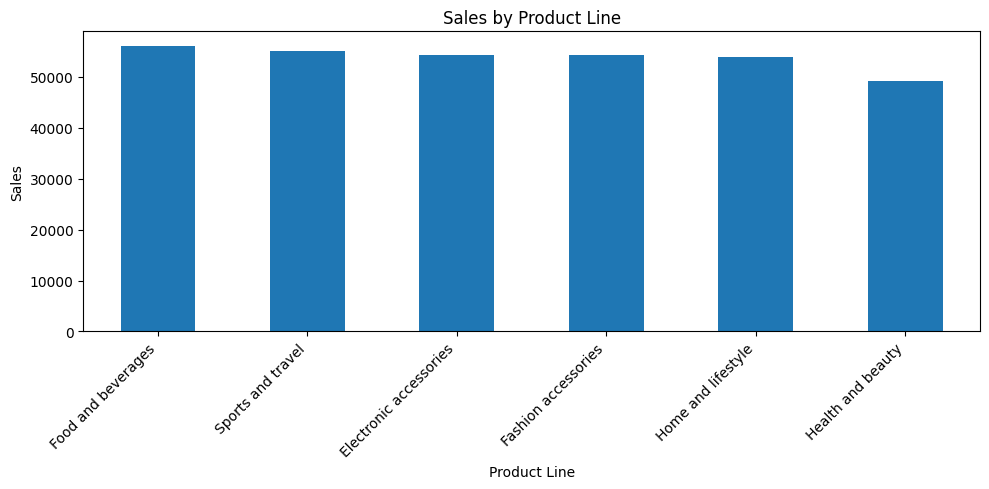

In [23]:

import matplotlib.pyplot as plt

# Calculate total sales by product line
sales_by_product = (
    df.groupby('Product line')['Sales']
    .sum()
    .sort_values(ascending=False)
)

# Create the bar chart
sales_by_product.plot(kind='bar', figsize=(10, 5))

plt.title('Sales by Product Line')
plt.xlabel('Product Line')
plt.ylabel('Sales')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [24]:
print(sales_by_product.round(2))

Product line
Food and beverages        56144.84
Sports and travel         55122.83
Electronic accessories    54337.53
Fashion accessories       54305.90
Home and lifestyle        53861.91
Health and beauty         49193.74
Name: Sales, dtype: float64


### 3.2 Sales by Branch

This analysis compares total sales across branches to identify differences in revenue performance.

In [25]:
# Calculate total sales by branch
sales_by_branch = (
    df.groupby('Branch')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_branch.round(2))

Branch
Giza     110568.71
Alex     106200.37
Cairo    106197.67
Name: Sales, dtype: float64


### 3.3 Branch Transactions and Average Sales

This analysis compares the number of transactions and average sales value across branches.

In [45]:
# Count transactions by branch
transactions_by_branch = df.groupby('Branch')['Invoice ID'].nunique()

# Calculate average transaction value by branch
average_transaction_value_by_branch = df.groupby('Branch')['Sales'].mean()

# Combine metrics into a single table
branch_comparison = pd.DataFrame({
    'Number of Transactions': transactions_by_branch,
    'Average Transaction Value': average_transaction_value_by_branch
})

print(branch_comparison.round(2))

        Number of Transactions  Average Transaction Value
Branch                                                   
Alex                       340                     312.35
Cairo                      332                     319.87
Giza                       328                     337.10


### 3.4 Payment Methods

This analysis examines the distribution of transactions across payment methods.

In [15]:
# Count transactions by payment method
payment_counts = df['Payment'].value_counts()

print(payment_counts)

Payment
Ewallet        345
Cash           344
Credit card    311
Name: count, dtype: int64


### 3.5 Daily Sales Trends

The date column was converted to a datetime format to support daily and monthly sales analysis.

In [32]:
# Convert the Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')

# Display the first five dates
print(df['Date'].head())

0   2019-01-05
1   2019-03-08
2   2019-03-03
3   2019-01-27
4   2019-02-08
Name: Date, dtype: datetime64[ns]


In [33]:
# Calculate total sales for each day
daily_sales = df.groupby('Date')['Sales'].sum()

# Display the 10 days with the highest sales
print(daily_sales.sort_values(ascending=False).head(10).round(2))

Date
2019-03-09    7474.05
2019-02-07    7228.21
2019-03-14    7214.63
2019-02-15    6830.79
2019-03-02    6560.31
2019-03-05    6230.88
2019-01-23    5994.19
2019-01-15    5944.26
2019-02-27    5859.45
2019-03-19    5740.39
Name: Sales, dtype: float64


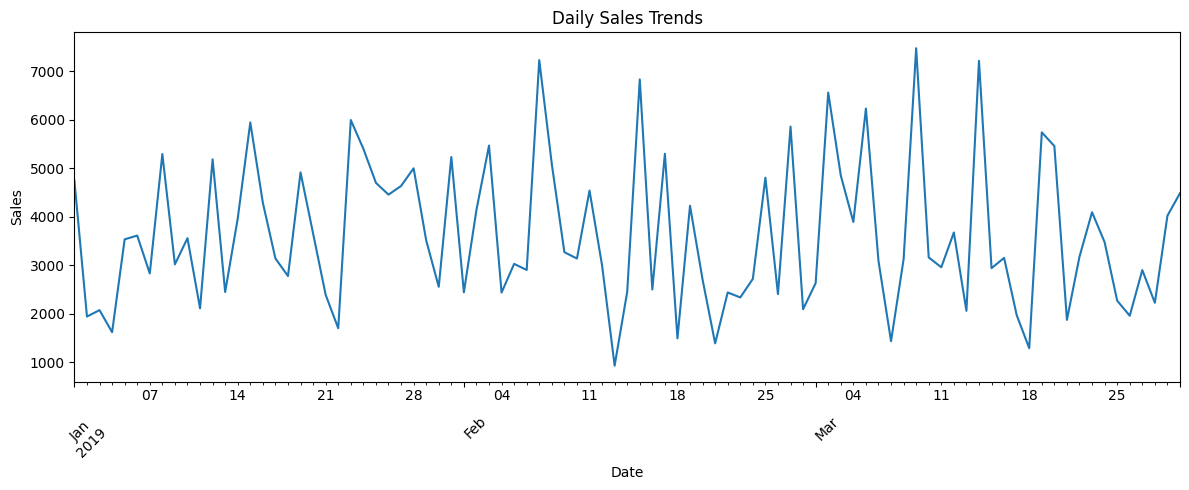

In [34]:
import matplotlib.pyplot as plt

# Sort daily sales chronologically
daily_sales = daily_sales.sort_index()

# Create the daily sales chart
daily_sales.plot(figsize=(12, 5))

plt.title('Daily Sales Trends')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 3.6 Monthly Sales Performance

This analysis compares total sales across the three months covered by the dataset.

In [30]:
# Create a column representing the sales month
df['Month'] = df['Date'].dt.to_period('M')

# Calculate total sales by month
monthly_sales = df.groupby('Month')['Sales'].sum()

print(monthly_sales.round(2))

Month
2019-01    116291.87
2019-02     97219.37
2019-03    109455.51
Freq: M, Name: Sales, dtype: float64


### 3.7 Sales by Branch and Product Line

This analysis compares product category revenue across branches using a pivot table and heatmap.

In [31]:
# Calculate sales by branch and product line
sales_by_branch_category = pd.pivot_table(
    df,
    values='Sales',
    index='Branch',
    columns='Product line',
    aggfunc='sum'
)

print(sales_by_branch_category.round(2))

Product line  Electronic accessories  Fashion accessories  Food and beverages  \
Branch                                                                          
Alex                        18317.11             16332.51            17163.10   
Cairo                       17051.44             16413.32            15214.89   
Giza                        18968.97             21560.07            23766.86   

Product line  Health and beauty  Home and lifestyle  Sports and travel  
Branch                                                                  
Alex                   12597.75            22417.20           19372.70  
Cairo                  19980.66            17549.16           19988.20  
Giza                   16615.33            13895.55           15761.93  


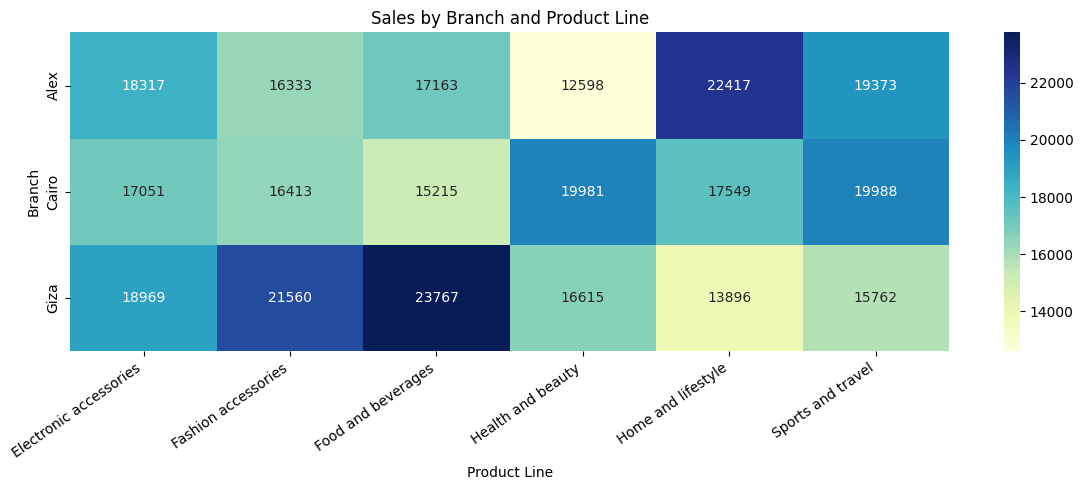

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create a heatmap of sales by branch and product line
plt.figure(figsize=(12, 5))

sns.heatmap(
    sales_by_branch_category,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Sales by Branch and Product Line')
plt.xlabel('Product Line')
plt.ylabel('Branch')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

In [42]:
# Convert the Date column to datetime format
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')

# Verify the data type
print(df['Date'].dtype)

datetime64[ns]


## 4. Key Business Metrics

These metrics summarize overall sales performance, average transaction value, customer ratings, and the highest-performing branch and product line.

In [44]:

# Calculate key business metrics

total_sales = df['Sales'].sum()
total_transactions = df['Invoice ID'].nunique()
average_transaction_value = total_sales / total_transactions
average_customer_rating = df['Rating'].mean()

top_product_line = df.groupby('Product line')['Sales'].sum().idxmax()
top_branch = df.groupby('Branch')['Sales'].sum().idxmax()
best_month = df.groupby(df['Date'].dt.to_period('M'))['Sales'].sum().idxmax()

# Display the results
print(f"Total sales: {total_sales:,.2f}")
print(f"Total transactions: {total_transactions}")
print(f"Average transaction value: {average_transaction_value:,.2f}")
print(f"Average customer rating: {average_customer_rating:.2f}/10")
print(f"Top product line: {top_product_line}")
print(f"Top branch by sales: {top_branch}")
print(f"Best month: {best_month}")


Total sales: 322,966.75
Total transactions: 1000
Average transaction value: 322.97
Average customer rating: 6.97/10
Top product line: Food and beverages
Top branch by sales: Giza
Best month: 2019-01



## 5. Key Findings and Business Recommendations

### Key Findings

- **Total sales:** The dataset recorded 322,966.75 in total sales across 1,000 transactions.
- **Average transaction value:** The average sales value per transaction was 322.97.
- **Product performance:** Food and beverages was the highest-performing product line by total sales, while Health and beauty recorded the lowest total sales.
- **Branch performance:** Giza generated the highest total sales (110,568.71), despite having fewer transactions than Alex.
- **Customer ratings:** The average customer rating was 6.97 out of 10.
- **Monthly performance:** January 2019 recorded the highest total sales among the three months analyzed.

### Business Recommendations

- Investigate what drives the strong sales performance of Food and beverages and whether successful practices can be applied to other product lines.
- Analyze Giza's higher average transaction value to identify opportunities to increase spending per transaction at other branches.
- Review customer feedback and ratings to identify potential improvements in the shopping experience.
- Investigate the decline in sales from January to February and the subsequent recovery in March, while considering that the dataset covers only three months.

### Limitations

This analysis covers three months of sales data from 2019. The findings describe this dataset and should not be treated as evidence of current performance or long-term seasonal trends.
